# Week 1 Project: Python for Machine Learning & Data Preprocessing
**Programme:** AI Pioneers Internship (Machine Learning) – Yuva Intern  
**Task:** Week 1 – Python fundamentals, NumPy, Pandas, data cleaning, feature selection, encoding, normalization and EDA  

---
## ⚠️ Dataset disclosure (please read)
The dataset used in this project (`data/raw_dataset.csv`) is **SYNTHETIC (computer-generated)**. It is **not** real student data and it was **not** downloaded from any public source.  
It was created with NumPy by `scripts/generate_dataset.py` using a fixed random seed (`42`), so it can be reproduced exactly.  
Realistic data-quality problems (missing values, duplicate rows, inconsistent text, impossible values, numbers stored as text) were **deliberately injected** so that the cleaning steps have real work to do.  
Because the target column `final_score` was built from a formula plus random noise, any patterns found in the EDA reflect how the data was generated – they are **not** findings about real students.

## Notebook contents
1. Setup
2. Python fundamentals (quick demo)
3. NumPy basics (quick demo)
4. Loading and inspecting the data (Pandas)
5. Data cleaning (duplicates, text, types, impossible values, missing values, outliers)
6. Export the cleaned dataset
7. Feature selection
8. Categorical encoding
9. Numerical normalization
10. Exploratory Data Analysis (EDA)
11. Export ML-ready dataset and verification
12. Summary

## 1. Setup
Import the libraries we need and set display options. All paths are relative to the `notebooks/` folder.

In [ ]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f_oneway   # simple statistical test used in feature selection

# Display options so tables are easy to read
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

# Folders used by this notebook
os.makedirs("../figures", exist_ok=True)
os.makedirs("../outputs", exist_ok=True)

# Dictionary that will collect numbers for the project report
stats = {}

print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)

## 2. Python fundamentals (quick demo)
Before using Pandas, here are the core Python ideas used later in the notebook: variables, lists, dictionaries, loops, functions, conditions and list comprehensions.

In [ ]:
# Variables and basic data types
student_name = "Sample Student"      # str
study_hours = 14.5                   # float
age = 20                             # int
has_internet = True                  # bool
print(type(student_name), type(study_hours), type(age), type(has_internet))

# List and dictionary
scores = [55, 72, 68, 90, 41]                          # list of numbers
student = {"name": student_name, "age": age, "scores": scores}   # dictionary
print("First score:", scores[0], "| Last score:", scores[-1])
print("Student dictionary keys:", list(student.keys()))

# A function with a condition
def grade(score):
    """Return a simple grade label for a score out of 100."""
    if score >= 75:
        return "Distinction"
    elif score >= 50:
        return "Pass"
    else:
        return "Fail"

# A for-loop and a list comprehension doing the same job
for s in scores:
    print(s, "->", grade(s))
grades = [grade(s) for s in scores]
print("Grades list:", grades)

<class 'str'> <class 'float'> <class 'int'> <class 'bool'>
First score: 55 | Last score: 41
Student dictionary keys: ['name', 'age', 'scores']
55 -> Pass
72 -> Pass
68 -> Pass
90 -> Distinction
41 -> Fail
Grades list: ['Pass', 'Pass', 'Pass', 'Distinction', 'Fail']


## 3. NumPy basics (quick demo)
NumPy gives us fast arrays. Pandas is built on top of NumPy, so these ideas appear again inside DataFrames.

In [ ]:
arr = np.array(scores)                 # list -> NumPy array
print("Array          :", arr)
print("Shape / dtype  :", arr.shape, arr.dtype)
print("Mean / median  :", arr.mean(), "/", np.median(arr))
print("Std deviation  :", round(arr.std(), 2))
print("Min / Max      :", arr.min(), "/", arr.max())

# Vectorised maths (no loop needed)
print("Scores + 5     :", arr + 5)

# Boolean mask and np.where
print("Scores >= 50   :", arr[arr >= 50])
print("Pass/Fail      :", np.where(arr >= 50, "Pass", "Fail"))

# Min-max normalization written by hand with NumPy (we use the same idea on the real data later)
print("Min-max scaled :", np.round((arr - arr.min()) / (arr.max() - arr.min()), 3))

Array          : [55 72 68 90 41]
Shape / dtype  : (5,) int64
Mean / median  : 65.2 / 68.0
Std deviation  : 16.49
Min / Max      : 41 / 90
Scores + 5     : [60 77 73 95 46]
Scores >= 50   : [55 72 68 90]
Pass/Fail      : ['Pass' 'Pass' 'Pass' 'Pass' 'Fail']
Min-max scaled : [0.286 0.633 0.551 1.    0.   ]


## 4. Loading and inspecting the data (Pandas)
We load the raw CSV and keep an untouched copy (`raw`) so we can always compare with the original.

In [ ]:
raw = pd.read_csv("../data/raw_dataset.csv")   # load the CSV file
df = raw.copy()                                # work on a copy, keep raw untouched

print("Shape (rows, columns):", df.shape)
stats["raw_rows"], stats["raw_cols"] = int(df.shape[0]), int(df.shape[1])
df.head(10)

Shape (rows, columns): (525, 12)


,student_id,age,gender,department,study_hours_per_week,attendance_percent,sleep_hours,previous_score,internet_access,parental_education,extracurricular,final_score
0,S0311,NaN,male,Arts,12.5,64.0,8.9,62.6,Yes,Master,yes,62.4
1,S0391,0.0,Female,Electronics,13.1,76.6,8.1,NaN,Yes,Master,No,67.5
2,S0007,17.0,Female,Electronics,14.7,92.6,6.9,67.5,No,Bachelor,Yes,69.4
3,S0185,20.0,Male,Commerce,18.5,74.6,6.1,NaN,Yes,High School,Yes,67.5
4,S0079,21.0,Female,arts,168.0,83.3%,8.1,54.0,Yes,High School,No,50.6
5,S0408,18.0,Male,Computer Science,15.3,80.5,6.0,67.6,Yes,High School,Yes,70.1
6,S0077,19.0,Female,Mechanical,16.0,60.1,7.3,85.7,Yes,High School,Yes,67.1
7,S0488,21.0,Male,Electronics,12.0,77.9,5.6,81.3,Yes,Bachelor,Yes,65.3
8,S0118,18.0,Female,Commerce,8.6,NaN,5.1,78.7,Yes,Master,No,74.0
9,S0138,17.0,Female,Computer Science,18.4,82.8,7.5,85.0,Yes,Bachelor,Yes,75.1


In [ ]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 525 entries, 0 to 524
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            525 non-null    str    
 1   age                   505 non-null    float64
 2   gender                510 non-null    str    
 3   department            525 non-null    str    
 4   study_hours_per_week  493 non-null    float64
 5   attendance_percent    498 non-null    str    
 6   sleep_hours           498 non-null    float64
 7   previous_score        505 non-null    float64
 8   internet_access       508 non-null    str    
 9   parental_education    500 non-null    str    
 10  extracurricular       525 non-null    str    
 11  final_score           517 non-null    float64
dtypes: float64(5), str(7)
memory usage: 49.3 KB


In [ ]:
# Statistical summary of numeric columns - look at min and max for suspicious values
df.describe().round(2)

,age,study_hours_per_week,sleep_hours,previous_score,final_score
count,505.00,493.00,498.00,505.00,517.00
mean,20.63,15.41,6.88,66.11,64.18
std,4.40,11.08,1.44,15.93,9.94
min,-3.00,1.00,0.00,26.60,34.00
25%,19.00,10.70,6.10,55.80,57.40
50%,20.00,14.90,6.90,65.60,64.30
75%,23.00,18.90,7.70,75.50,70.50
max,99.00,168.00,25.00,250.00,100.00


In [ ]:
# Missing values per column (count and percent)
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(2)
})
stats["missing_raw"] = {k: int(v) for k, v in df.isnull().sum().items()}
missing[missing.missing_count > 0].sort_values("missing_count", ascending=False)

,missing_count,missing_percent
study_hours_per_week,32,6.10
sleep_hours,27,5.14
attendance_percent,27,5.14
parental_education,25,4.76
age,20,3.81
previous_score,20,3.81
internet_access,17,3.24
gender,15,2.86
final_score,8,1.52


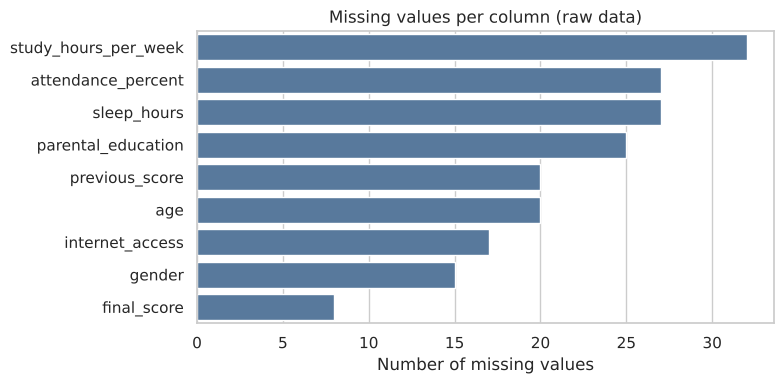

In [ ]:
# Visualise missing values
plt.figure(figsize=(8, 4))
miss_plot = df.isnull().sum().sort_values(ascending=False)
miss_plot = miss_plot[miss_plot > 0]
sns.barplot(x=miss_plot.values, y=miss_plot.index, color="#4C78A8")
plt.title("Missing values per column (raw data)")
plt.xlabel("Number of missing values")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../figures/fig01_missing_values.png", dpi=150)
plt.show()

In [ ]:
# Duplicate rows
n_dup = int(df.duplicated().sum())
stats["duplicates_found"] = n_dup
print("Exact duplicate rows:", n_dup)
df[df.duplicated(keep=False)].sort_values("student_id").head(6)

Exact duplicate rows: 25


,student_id,age,gender,department,study_hours_per_week,attendance_percent,sleep_hours,previous_score,internet_access,parental_education,extracurricular,final_score
444,S0010,17.0,Female,Electronics,19.7,100.0,5.9,67.5,Yes,Bachelor,No,80.1
38,S0010,17.0,Female,Electronics,19.7,100.0,5.9,67.5,Yes,Bachelor,No,80.1
128,S0031,20.0,Male,computer science,21.3,88.1,7.3,79.3,Yes,Master,Yes,76.0
34,S0031,20.0,Male,computer science,21.3,88.1,7.3,79.3,Yes,Master,Yes,76.0
472,S0069,17.0,Male,MECHANICAL,2.9,50.8,NaN,72.0,Yes,Bachelor,Yes,54.5
37,S0069,17.0,Male,MECHANICAL,2.9,50.8,NaN,72.0,Yes,Bachelor,Yes,54.5


In [ ]:
# Look at categorical columns: inconsistent spelling shows up as extra categories
for col in ["gender", "department", "internet_access", "parental_education", "extracurricular"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).to_string())
    print()

--- gender ---
gender
Female     222
Male       211
NaN         15
male        14
Other       13
F           11
M           11
 Male        9
female       9
other        6
FEMALE       4

--- department ---
department
Computer Science     148
Electronics           95
Commerce              92
Arts                  77
Mechanical            59
MECHANICAL            12
electronics           10
CS                     8
commerce               8
arts                   6
computer science       6
 Computer Science      4

--- internet_access ---
internet_access
Yes    389
No      78
Y       20
yes     17
NaN     17
N        3
no       1

--- parental_education ---
parental_education
Bachelor       198
High School    166
Master          83
NaN             25
PhD             22
high school     18
bachelor        10
master           3

--- extracurricular ---
extracurricular
No     268
Yes    237
yes     13
no       7



### What we found during inspection
- **Duplicate rows** exist (counted above).
- **Missing values** appear in most columns, including a few rows where the target `final_score` is missing.
- **Inconsistent text**: the same category is written in different ways (e.g. `male`, `M`, ` Male`).
- **Wrong data type**: `attendance_percent` is read as text because some rows contain a `%` sign.
- **Impossible values** (e.g. negative age, attendance above 100, sleep of 25 hours) – we will check these with explicit rules.

## 5. Data cleaning
Each step is applied to `df` and its effect is recorded in a small `log` dictionary used later in the report.

In [ ]:
log = {}   # records what each cleaning step changed
log["rows_raw"] = len(df)

### Step 1 – Remove duplicate rows
Exact duplicate rows add no new information and can bias results, so we keep only the first copy.

In [ ]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log["duplicates_removed"] = before - len(df)
print(f"Rows before: {before} | after: {len(df)} | removed: {log['duplicates_removed']}")

Rows before: 525 | after: 500 | removed: 25


### Step 2 – Standardise text categories
We remove extra spaces, make capitalisation consistent, then map short forms (`M`, `F`, `Y`, `N`, `CS`) to full names.

In [ ]:
text_cols = ["gender", "department", "internet_access", "parental_education", "extracurricular"]

# 2a. strip spaces + Title Case  (' MECHANICAL ' -> 'Mechanical')
for col in text_cols:
    df[col] = df[col].str.strip().str.title()

# 2b. map short forms / odd capitalisation to the proper label
fix_map = {"M": "Male", "F": "Female", "Y": "Yes", "N": "No",
           "Cs": "Computer Science", "Phd": "PhD"}
for col in text_cols:
    df[col] = df[col].replace(fix_map)

for col in text_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).to_string())
    print()

# Safety check: every category must now be one of the expected labels
expected = {
    "gender": {"Male", "Female", "Other"},
    "department": {"Computer Science", "Electronics", "Mechanical", "Commerce", "Arts"},
    "internet_access": {"Yes", "No"},
    "parental_education": {"High School", "Bachelor", "Master", "PhD"},
    "extracurricular": {"Yes", "No"},
}
for col, allowed in expected.items():
    assert set(df[col].dropna().unique()) <= allowed, f"Unexpected label in {col}"
print("All category labels are consistent.")

--- gender ---
gender
Male      235
Female    232
Other      18
NaN        15

--- department ---
department
Computer Science    159
Electronics          97
Commerce             95
Arts                 82
Mechanical           67

--- internet_access ---
internet_access
Yes    405
No      80
NaN     15

--- parental_education ---
parental_education
Bachelor       197
High School    174
Master          83
NaN             25
PhD             21

--- extracurricular ---
extracurricular
No     261
Yes    239

All category labels are consistent.


### Step 3 – Fix wrong data types
`attendance_percent` contains values like `82.5%`. We remove the `%` sign and convert the column to numbers.

In [ ]:
log["attendance_text_values_fixed"] = int(df["attendance_percent"].astype(str).str.contains("%").sum())
df["attendance_percent"] = pd.to_numeric(
    df["attendance_percent"].astype(str).str.replace("%", "", regex=False), errors="coerce"
)
print("Rows that had a % sign:", log["attendance_text_values_fixed"])
print("New dtype:", df["attendance_percent"].dtype)

Rows that had a % sign: 37
New dtype: float64


### Step 4 – Replace impossible values with missing values
We define a sensible valid range for each numeric column. Values outside the range are data-entry errors, so we turn them into `NaN` and treat them together with the other missing values in the next step.

In [ ]:
valid_ranges = {
    "age": (15, 40),
    "study_hours_per_week": (0, 60),
    "attendance_percent": (0, 100),
    "sleep_hours": (3, 12),
    "previous_score": (0, 100),
    "final_score": (0, 100),
}

invalid_counts = {}
for col, (low, high) in valid_ranges.items():
    bad = df[col].notna() & ~df[col].between(low, high)
    invalid_counts[col] = int(bad.sum())
    if bad.sum() > 0:
        print(f"{col}: invalid values -> {sorted(df.loc[bad, col].tolist())}")
    df.loc[bad, col] = np.nan

log["impossible_values_set_to_nan"] = int(sum(invalid_counts.values()))
stats["invalid_counts"] = invalid_counts
print("\nInvalid values per column:", invalid_counts)

age: invalid values -> [-3.0, 0.0, 99.0]
study_hours_per_week: invalid values -> [95.0, 120.0, 168.0]
attendance_percent: invalid values -> [-5.0, 130.0, 150.0]
sleep_hours: invalid values -> [0.0, 25.0]
previous_score: invalid values -> [250.0]

Invalid values per column: {'age': 3, 'study_hours_per_week': 3, 'attendance_percent': 3, 'sleep_hours': 2, 'previous_score': 1, 'final_score': 0}


### Step 5 – Handle missing values
- **Target (`final_score`)**: rows with a missing target are dropped, because inventing the answer we want to predict would be misleading.
- **Numeric features**: filled with the **median** (not affected by extreme values).
- **Categorical features**: filled with the **mode** (most frequent category).

In [ ]:
# 5a. drop rows with a missing target
before = len(df)
df = df.dropna(subset=["final_score"]).reset_index(drop=True)
log["rows_dropped_missing_target"] = before - len(df)
print("Rows dropped because final_score was missing:", log["rows_dropped_missing_target"])

# 5b. missing values left after the steps above
print("\nMissing values before filling:")
miss_before = df.isnull().sum()
stats["missing_before_fill"] = {k: int(v) for k, v in miss_before.items() if v > 0}
print(miss_before[miss_before > 0].to_string())

Rows dropped because final_score was missing: 8

Missing values before filling:
age                     23
gender                  15
study_hours_per_week    32
attendance_percent      27
sleep_hours             27
previous_score          21
internet_access         15
parental_education      24


In [ ]:
numeric_features = ["age", "study_hours_per_week", "attendance_percent", "sleep_hours", "previous_score"]
categorical_features = ["gender", "department", "internet_access", "parental_education", "extracurricular"]

fill_values = {}
# numeric -> median
for col in numeric_features:
    med = df[col].median()
    fill_values[col] = float(round(med, 2))
    df[col] = df[col].fillna(med)

# categorical -> mode (most frequent value)
for col in categorical_features:
    mode_val = df[col].mode()[0]
    fill_values[col] = str(mode_val)
    df[col] = df[col].fillna(mode_val)

stats["fill_values"] = fill_values
log["missing_values_filled"] = int(sum(stats["missing_before_fill"].values()))
print("Values used for filling:", fill_values)
print("\nMissing values after filling:", int(df.isnull().sum().sum()))

Values used for filling: {'age': 20.0, 'study_hours_per_week': 14.9, 'attendance_percent': 79.6, 'sleep_hours': 6.8, 'previous_score': 65.3, 'gender': 'Female', 'department': 'Computer Science', 'internet_access': 'Yes', 'parental_education': 'Bachelor', 'extracurricular': 'No'}

Missing values after filling: 0


### Step 6 – Convert data types
`age` is a whole number, so we store it as an integer.

In [ ]:
df["age"] = df["age"].round().astype(int)
df.dtypes

student_id                  str
age                       int64
gender                      str
department                  str
study_hours_per_week    float64
attendance_percent      float64
sleep_hours             float64
previous_score          float64
internet_access             str
parental_education          str
extracurricular             str
final_score             float64
dtype: object

### Step 7 – Detect and cap outliers (IQR rule)
The IQR rule treats a value as an outlier if it is below `Q1 - 1.5 x IQR` or above `Q3 + 1.5 x IQR`.  
Instead of deleting rows, we **cap** (clip) such values to the boundary. A copy is kept so we can show a before/after comparison.

In [ ]:
before_cap = df.copy()
outlier_report = {}
for col in numeric_features:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[col] < low) | (df[col] > high)).sum())
    outlier_report[col] = {"lower": round(float(low), 2), "upper": round(float(high), 2), "outliers": n_out}
    df[col] = df[col].clip(lower=low, upper=high)

# age should stay a whole number after capping
df["age"] = df["age"].round().astype(int)

stats["outlier_report"] = outlier_report
log["outliers_capped"] = int(sum(v["outliers"] for v in outlier_report.values()))
pd.DataFrame(outlier_report).T

,lower,upper,outliers
age,14.50,26.50,0.0
study_hours_per_week,-0.10,29.50,2.0
attendance_percent,50.10,107.70,3.0
sleep_hours,3.85,9.85,0.0
previous_score,27.35,103.95,1.0


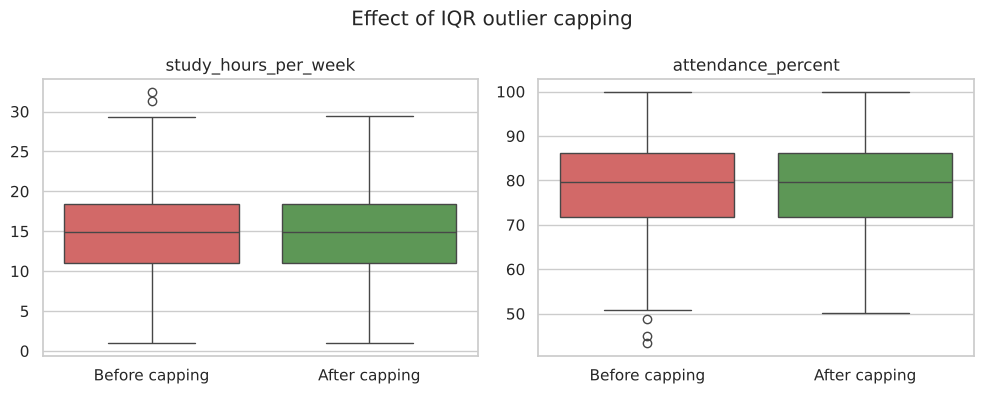

In [ ]:
# Before / after comparison for two columns
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["study_hours_per_week", "attendance_percent"]):
    data = pd.DataFrame({"Before capping": before_cap[col], "After capping": df[col]})
    sns.boxplot(data=data, ax=ax, palette=["#E45756", "#54A24B"])
    ax.set_title(col)
plt.suptitle("Effect of IQR outlier capping")
plt.tight_layout()
plt.savefig("../figures/fig02_outlier_capping.png", dpi=150)
plt.show()

In [ ]:
# Final checks for the cleaned data
log["rows_clean"] = len(df)
print("Final shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
stats["clean_rows"], stats["clean_cols"] = int(df.shape[0]), int(df.shape[1])
stats["log"] = log
pd.Series(log, name="count").to_frame()

Final shape: (492, 12)
Missing values: 0
Duplicate rows: 0


,count
rows_raw,525
duplicates_removed,25
attendance_text_values_fixed,37
impossible_values_set_to_nan,12
rows_dropped_missing_target,8
missing_values_filled,184
outliers_capped,6
rows_clean,492


## 6. Export the cleaned dataset

In [ ]:
df.to_csv("../data/cleaned_dataset.csv", index=False)

# Verify by reading the file back
check = pd.read_csv("../data/cleaned_dataset.csv")
print("Saved ../data/cleaned_dataset.csv with shape:", check.shape)
print("Same shape as df:", check.shape == df.shape, "| Missing values:", int(check.isnull().sum().sum()))
check.head()

Saved ../data/cleaned_dataset.csv with shape: (492, 12)
Same shape as df: True | Missing values: 0


,student_id,age,gender,department,study_hours_per_week,attendance_percent,sleep_hours,previous_score,internet_access,parental_education,extracurricular,final_score
0,S0311,20,Male,Arts,12.5,64.0,8.9,62.6,Yes,Master,Yes,62.4
1,S0391,20,Female,Electronics,13.1,76.6,8.1,65.3,Yes,Master,No,67.5
2,S0007,17,Female,Electronics,14.7,92.6,6.9,67.5,No,Bachelor,Yes,69.4
3,S0185,20,Male,Commerce,18.5,74.6,6.1,65.3,Yes,High School,Yes,67.5
4,S0079,21,Female,Arts,14.9,83.3,8.1,54.0,Yes,High School,No,50.6


## 7. Feature selection
Not every column helps a machine-learning model. We use three simple, beginner-level checks:
1. **Remove identifiers** – `student_id` is only a label, not a useful feature.
2. **Numeric features** – keep those whose absolute correlation with the target `final_score` is at least **0.10**.
3. **Categorical features** – compare `final_score` across the categories with a one-way ANOVA test (`scipy.stats.f_oneway`). If the **p-value is below 0.05**, the difference between group averages is unlikely to be pure chance, so we keep the feature.

These thresholds (0.10 and 0.05) are common rules of thumb fixed *before* looking at the results; they are not universal rules. Selection here is a simple *filter* check only; no model is trained.

In [ ]:
# 7a. Identifier column is dropped from the feature list
print("Dropped as identifier: student_id")

# 7b. Correlation of numeric features with the target
corr_target = df[numeric_features + ["final_score"]].corr()["final_score"].drop("final_score").round(3)
print("Correlation with final_score:")
print(corr_target.sort_values(ascending=False).to_string())

CORR_THRESHOLD = 0.10
selected_numeric = [c for c in numeric_features if abs(corr_target[c]) >= CORR_THRESHOLD]
dropped_numeric = [c for c in numeric_features if c not in selected_numeric]
print("\nSelected numeric features:", selected_numeric)
print("Dropped numeric features :", dropped_numeric)

stats["corr_target"] = {k: float(v) for k, v in corr_target.items()}
stats["selected_numeric"], stats["dropped_numeric"] = selected_numeric, dropped_numeric

Dropped as identifier: student_id
Correlation with final_score:
previous_score          0.675
study_hours_per_week    0.543
attendance_percent      0.142
sleep_hours             0.036
age                    -0.029

Selected numeric features: ['study_hours_per_week', 'attendance_percent', 'previous_score']
Dropped numeric features : ['age', 'sleep_hours']


In [ ]:
# 7c. Check that selected numeric features are not almost copies of each other (multicollinearity)
feat_corr = df[selected_numeric].corr().round(2)
pairs = [(a, b, feat_corr.loc[a, b]) for i, a in enumerate(selected_numeric)
         for b in selected_numeric[i + 1:] if abs(feat_corr.loc[a, b]) > 0.80]
print("Feature pairs with |correlation| > 0.80:", pairs if pairs else "none")

# 7d. Categorical features: do the group averages of final_score differ more than chance would explain?
P_THRESHOLD = 0.05
gap, pvals = {}, {}
for col in categorical_features:
    groups = [g["final_score"].values for _, g in df.groupby(col)]
    means = df.groupby(col)["final_score"].mean()
    gap[col] = round(float(means.max() - means.min()), 2)          # gap between highest and lowest group mean
    pvals[col] = round(float(f_oneway(*groups).pvalue), 4)          # ANOVA p-value
cat_table = pd.DataFrame({"gap_in_group_means": pd.Series(gap), "anova_p_value": pd.Series(pvals)}).sort_values("anova_p_value")
print(cat_table.to_string())

selected_categorical = [c for c in categorical_features if pvals[c] < P_THRESHOLD]
dropped_categorical = [c for c in categorical_features if c not in selected_categorical]
print("\nSelected categorical features:", selected_categorical if selected_categorical else "none")
print("Dropped categorical features :", dropped_categorical)

stats["cat_pvalue"] = pvals
stats["cat_gap"] = gap
stats["selected_categorical"], stats["dropped_categorical"] = selected_categorical, dropped_categorical

Feature pairs with |correlation| > 0.80: none
                    gap_in_group_means  anova_p_value
internet_access                   1.45         0.2392
extracurricular                   0.91         0.3142
gender                            2.60         0.5796
department                        1.84         0.8034
parental_education                0.80         0.9563

Selected categorical features: none
Dropped categorical features : ['gender', 'department', 'internet_access', 'parental_education', 'extracurricular']


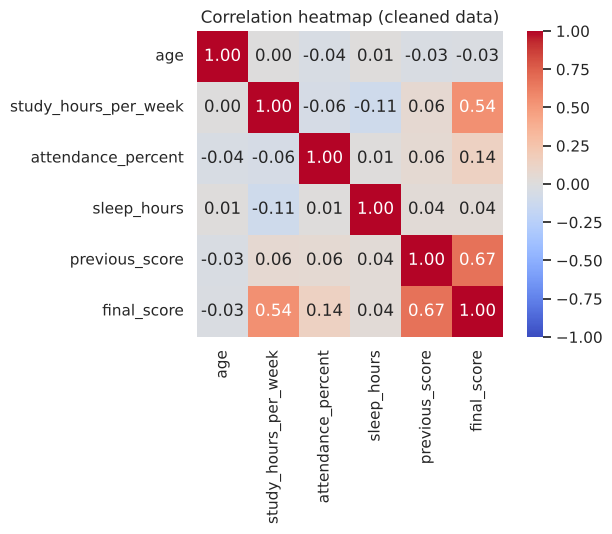

In [ ]:
# Heatmap of numeric correlations (features + target)
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[numeric_features + ["final_score"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation heatmap (cleaned data)")
plt.tight_layout()
plt.savefig("../figures/fig03_correlation_heatmap.png", dpi=150)
plt.show()

**Note:** Failing this filter does not prove a feature is useless – a small real effect can be hidden by noise in a few hundred rows. The filter is used here only to demonstrate how a simple feature-selection step works. The columns that were not selected are still encoded in Section 8 so they can be reused later.

## 8. Categorical encoding
Machine-learning models need numbers, so text categories are converted:
- **Binary mapping** (`Yes`/`No` -> 1/0) for two-value columns.
- **Ordinal encoding** for `parental_education`, which has a natural order (High School < Bachelor < Master < PhD).
- **One-hot encoding** (`pd.get_dummies`) for unordered categories such as `department` and `gender`. We use `drop_first=True` to avoid a redundant column.

To demonstrate all three methods, we encode **every** categorical column here, even those not selected in Section 7. Section 11 then exports both a full encoded file and a smaller file with the selected features only.

In [ ]:
encoded = df.copy()

# Binary mapping
yes_no = {"No": 0, "Yes": 1}
encoded["internet_access"] = encoded["internet_access"].map(yes_no)
encoded["extracurricular"] = encoded["extracurricular"].map(yes_no)

# Ordinal encoding (order matters)
edu_order = {"High School": 0, "Bachelor": 1, "Master": 2, "PhD": 3}
encoded["parental_education"] = encoded["parental_education"].map(edu_order)

# One-hot encoding for unordered categories
encoded = pd.get_dummies(encoded, columns=["department", "gender"], drop_first=True, dtype=int)

stats["encoding"] = {"binary": yes_no, "ordinal": edu_order,
                     "one_hot_columns": [c for c in encoded.columns if c.startswith(("department_", "gender_"))]}
print("Columns after encoding:", list(encoded.columns))
print("Any missing after encoding:", int(encoded.isnull().sum().sum()))
encoded.head()

Columns after encoding: ['student_id', 'age', 'study_hours_per_week', 'attendance_percent', 'sleep_hours', 'previous_score', 'internet_access', 'parental_education', 'extracurricular', 'final_score', 'department_Commerce', 'department_Computer Science', 'department_Electronics', 'department_Mechanical', 'gender_Male', 'gender_Other']
Any missing after encoding: 0


,student_id,age,study_hours_per_week,attendance_percent,sleep_hours,previous_score,internet_access,parental_education,extracurricular,final_score,department_Commerce,department_Computer Science,department_Electronics,department_Mechanical,gender_Male,gender_Other
0,S0311,20,12.5,64.0,8.9,62.6,1,2,1,62.4,0,0,0,0,1,0
1,S0391,20,13.1,76.6,8.1,65.3,1,2,0,67.5,0,0,1,0,0,0
2,S0007,17,14.7,92.6,6.9,67.5,0,1,1,69.4,0,0,1,0,0,0
3,S0185,20,18.5,74.6,6.1,65.3,1,0,1,67.5,1,0,0,0,1,0
4,S0079,21,14.9,83.3,8.1,54.0,1,0,0,50.6,0,0,0,0,0,0


## 9. Numerical normalization
Features have very different ranges (e.g. `attendance_percent` ~ 40-100 but `sleep_hours` ~ 4-10). Scaling puts them on a comparable range.
- **Min-max scaling:** `(x - min) / (max - min)` -> values between 0 and 1.
- **Z-score standardisation:** `(x - mean) / std` -> mean 0 and standard deviation 1 (shown for comparison).

All five numeric features are scaled. The target `final_score` is **not** scaled, and binary, ordinal and one-hot columns are left as they are.

In [ ]:
scale_cols = numeric_features          # all numeric features are scaled

minmax = encoded.copy()
zscore = encoded.copy()
for col in scale_cols:
    minmax[col] = (encoded[col] - encoded[col].min()) / (encoded[col].max() - encoded[col].min())
    zscore[col] = (encoded[col] - encoded[col].mean()) / encoded[col].std()

compare = pd.DataFrame({
    "original_min": encoded[scale_cols].min(), "original_max": encoded[scale_cols].max(),
    "minmax_min": minmax[scale_cols].min(), "minmax_max": minmax[scale_cols].max(),
    "zscore_mean": zscore[scale_cols].mean().round(6), "zscore_std": zscore[scale_cols].std().round(6),
}).round(3)
stats["scaling_table"] = compare.reset_index().rename(columns={"index": "feature"}).to_dict(orient="records")
compare

,original_min,original_max,minmax_min,minmax_max,zscore_mean,zscore_std
age,17.00,24.0,0.0,1.0,0.0,1.0
study_hours_per_week,1.00,29.5,0.0,1.0,0.0,1.0
attendance_percent,50.10,100.0,0.0,1.0,0.0,1.0
sleep_hours,4.00,9.8,0.0,1.0,-0.0,1.0
previous_score,27.35,100.0,0.0,1.0,0.0,1.0


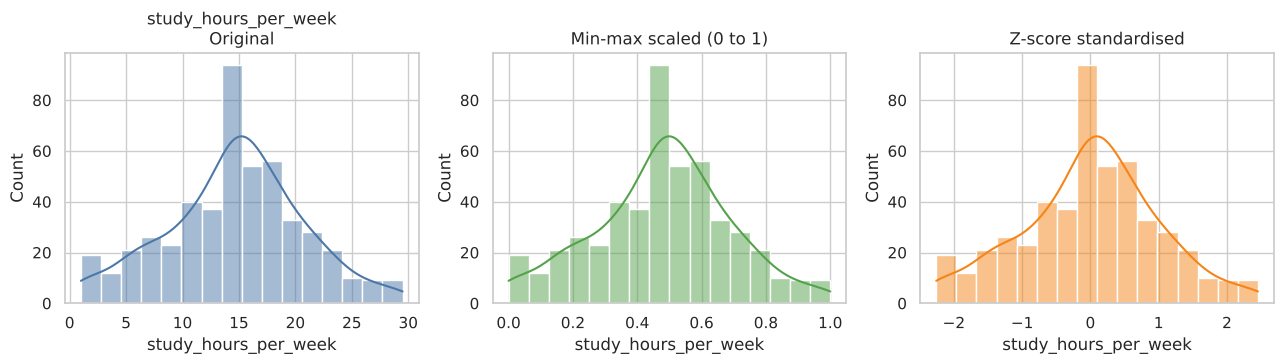

In [ ]:
# Visual comparison for one feature: shape stays the same, only the scale changes
col = "study_hours_per_week"
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
sns.histplot(encoded[col], kde=True, ax=axes[0], color="#4C78A8"); axes[0].set_title(f"{col}\nOriginal")
sns.histplot(minmax[col], kde=True, ax=axes[1], color="#54A24B"); axes[1].set_title("Min-max scaled (0 to 1)")
sns.histplot(zscore[col], kde=True, ax=axes[2], color="#F58518"); axes[2].set_title("Z-score standardised")
plt.tight_layout()
plt.savefig("../figures/fig04_normalization_comparison.png", dpi=150)
plt.show()
stats["scaling_demo_feature"] = col

## 10. Exploratory Data Analysis (EDA)
EDA uses the cleaned, human-readable dataset (`df`) so the charts show real units such as hours and marks.

### 10.1 Statistical summary

In [ ]:
num_summary = df[numeric_features + ["final_score"]].describe().T
num_summary["skewness"] = df[numeric_features + ["final_score"]].skew()
stats["eda_summary"] = num_summary.round(2).reset_index().rename(columns={"index": "feature"}).to_dict(orient="records")
num_summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness
age,492.0,20.49,2.24,17.00,19.00,20.00,22.00,24.0,0.03
study_hours_per_week,492.0,14.66,6.05,1.00,11.00,14.90,18.40,29.5,-0.10
attendance_percent,492.0,78.80,10.80,50.10,71.70,79.60,86.10,100.0,-0.15
sleep_hours,492.0,6.82,1.12,4.00,6.10,6.80,7.60,9.8,-0.12
previous_score,492.0,65.75,13.52,27.35,56.08,65.30,75.22,100.0,0.15
final_score,492.0,64.09,9.97,34.00,57.40,64.25,70.32,100.0,0.01


In [ ]:
# Categorical summary: counts and percentages
for col in categorical_features:
    out = pd.DataFrame({"count": df[col].value_counts(), "percent": (df[col].value_counts(normalize=True) * 100).round(1)})
    print(f"--- {col} ---")
    print(out.to_string())
    print()
stats["cat_counts"] = {c: df[c].value_counts().to_dict() for c in categorical_features}

--- gender ---
        count  percent
gender                
Female    245     49.8
Male      230     46.7
Other      17      3.5

--- department ---
                  count  percent
department                      
Computer Science    156     31.7
Commerce             95     19.3
Electronics          94     19.1
Arts                 81     16.5
Mechanical           66     13.4

--- internet_access ---
                 count  percent
internet_access                
Yes                414     84.1
No                  78     15.9

--- parental_education ---
                    count  percent
parental_education                
Bachelor              220     44.7
High School           169     34.3
Master                 82     16.7
PhD                    21      4.3

--- extracurricular ---
                 count  percent
extracurricular                
No                 257     52.2
Yes                235     47.8



### 10.2 Distributions of numeric features

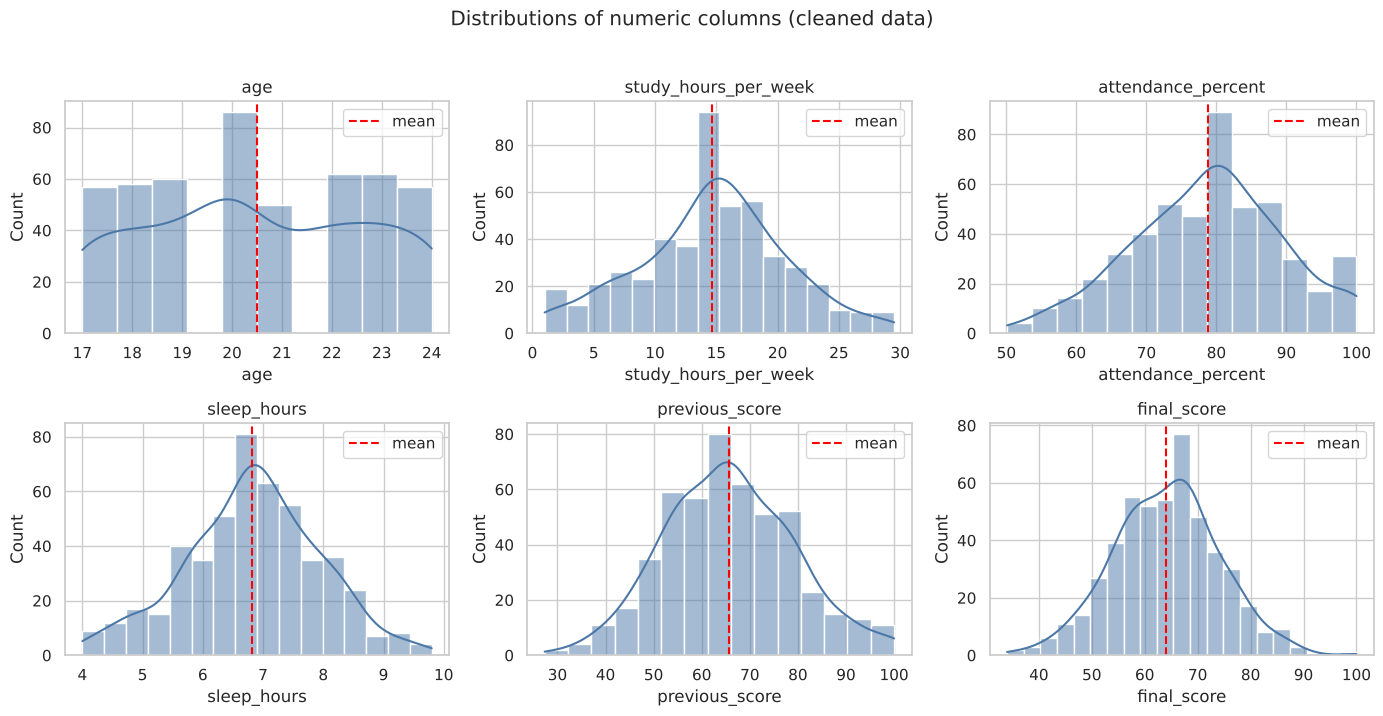

In [ ]:
cols = numeric_features + ["final_score"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#4C78A8")
    ax.axvline(df[col].mean(), color="red", linestyle="--", label="mean")
    ax.set_title(col); ax.legend()
plt.suptitle("Distributions of numeric columns (cleaned data)", y=1.02)
plt.tight_layout()
plt.savefig("../figures/fig05_numeric_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.3 Categorical features

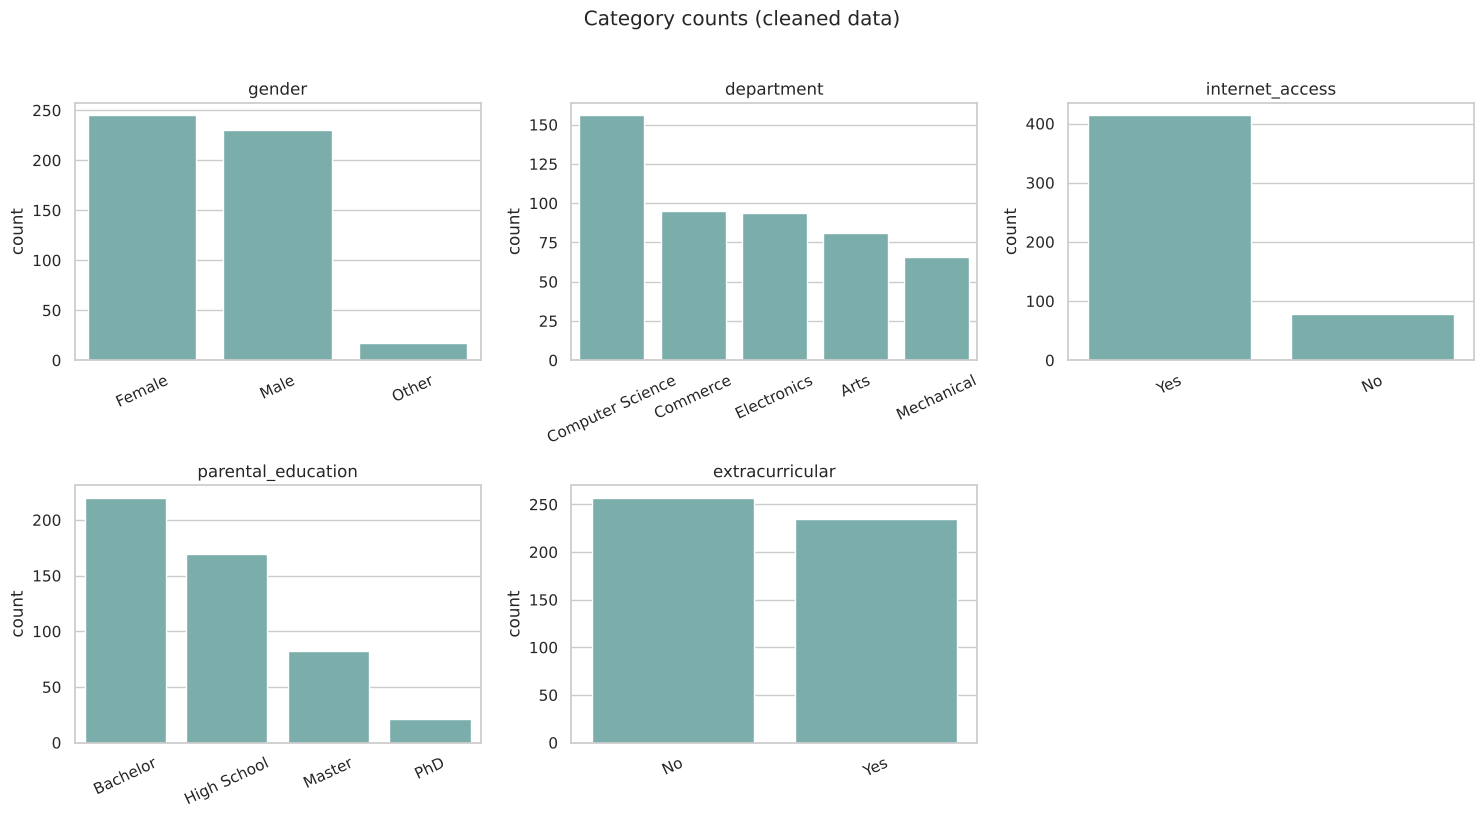

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), categorical_features):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, color="#72B7B2")
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
axes.ravel()[-1].axis("off")
plt.suptitle("Category counts (cleaned data)", y=1.02)
plt.tight_layout()
plt.savefig("../figures/fig06_categorical_counts.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.4 Relationship between features and the final score

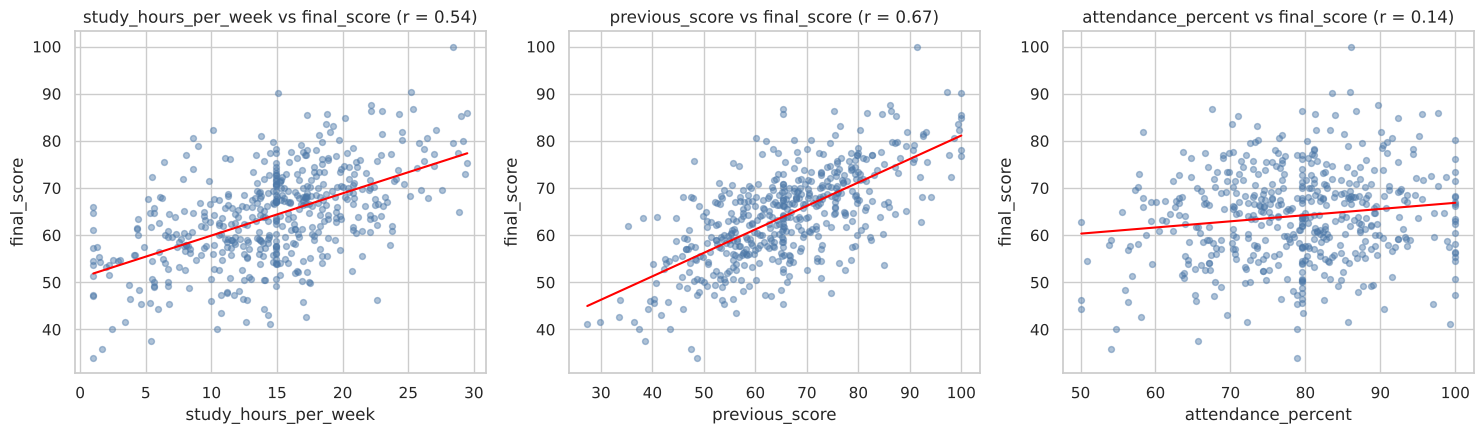

In [ ]:
# Scatter plots with a straight trend line computed by NumPy (np.polyfit)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ["study_hours_per_week", "previous_score", "attendance_percent"]):
    ax.scatter(df[col], df["final_score"], alpha=0.45, s=18, color="#4C78A8")
    slope, intercept = np.polyfit(df[col], df["final_score"], 1)
    xs = np.linspace(df[col].min(), df[col].max(), 100)
    ax.plot(xs, slope * xs + intercept, color="red")
    r = df[col].corr(df["final_score"])
    ax.set_title(f"{col} vs final_score (r = {r:.2f})")
    ax.set_xlabel(col); ax.set_ylabel("final_score")
plt.tight_layout()
plt.savefig("../figures/fig07_scatter_relationships.png", dpi=150)
plt.show()

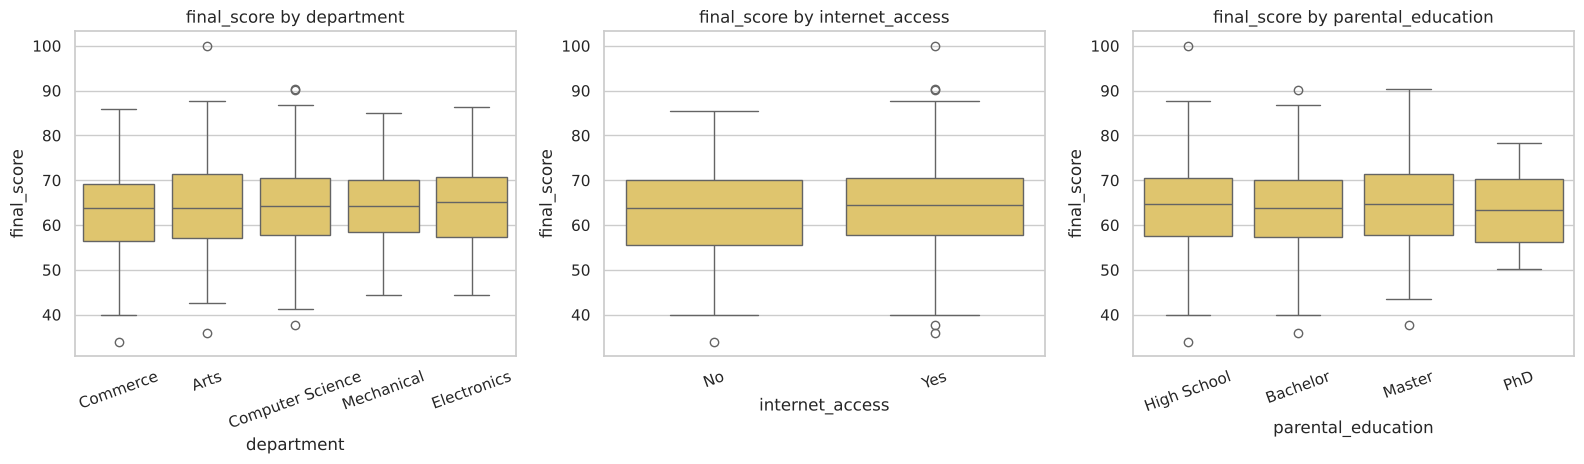

In [ ]:
# Final score by category (box plots)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, col in zip(axes, ["department", "internet_access", "parental_education"]):
    order = (["High School", "Bachelor", "Master", "PhD"] if col == "parental_education"
             else df.groupby(col)["final_score"].median().sort_values().index)
    sns.boxplot(data=df, x=col, y="final_score", order=order, ax=ax, color="#F2CF5B")
    ax.set_title(f"final_score by {col}"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("../figures/fig08_score_by_category.png", dpi=150)
plt.show()

In [ ]:
# Group averages in table form
group_tables = {}
for col in ["department", "internet_access", "extracurricular"]:
    t = df.groupby(col)["final_score"].agg(["count", "mean", "median"]).round(2).sort_values("mean", ascending=False)
    group_tables[col] = t.reset_index().to_dict(orient="records")
    print(f"--- Average final_score by {col} ---")
    print(t.to_string())
    print()
stats["group_tables"] = group_tables

--- Average final_score by department ---
                  count   mean  median
department                            
Arts                 81  65.02   63.90
Electronics          94  64.41   65.15
Mechanical           66  64.17   64.25
Computer Science    156  63.92   64.20
Commerce             95  63.19   63.80

--- Average final_score by internet_access ---
                 count   mean  median
internet_access                      
Yes                414  64.32    64.4
No                  78  62.87    63.7

--- Average final_score by extracurricular ---
                 count   mean  median
extracurricular                      
Yes                235  64.56    65.0
No                 257  63.65    63.8



### 10.5 Key observations (computed from the data)

In [ ]:
# These sentences are generated from the actual results, so they always match the data
top_corr = corr_target.abs().sort_values(ascending=False)
strongest = top_corr.index[0]
print(f"1. Cleaned dataset has {len(df)} rows and {df.shape[1]} columns with no missing values.")
print(f"2. Average final_score is {df['final_score'].mean():.1f} (median {df['final_score'].median():.1f}, std {df['final_score'].std():.1f}).")
print(f"3. Numeric feature most correlated with final_score: {strongest} (r = {corr_target[strongest]:.2f}).")
print(f"4. Weakest numeric correlation: {top_corr.index[-1]} (r = {corr_target[top_corr.index[-1]]:.2f}).")
inet = df.groupby("internet_access")["final_score"].mean().round(1).to_dict()
print(f"5. Average final_score by internet access: {inet}.")
print("6. These patterns come from how the synthetic data was generated; they are not real-world findings.")
stats["observations"] = {"strongest_feature": strongest, "strongest_r": float(corr_target[strongest]),
                         "weakest_feature": top_corr.index[-1], "weakest_r": float(corr_target[top_corr.index[-1]]),
                         "mean_final": float(df["final_score"].mean()), "median_final": float(df["final_score"].median()),
                         "std_final": float(df["final_score"].std()), "internet_means": inet}

1. Cleaned dataset has 492 rows and 12 columns with no missing values.
2. Average final_score is 64.1 (median 64.2, std 10.0).
3. Numeric feature most correlated with final_score: previous_score (r = 0.68).
4. Weakest numeric correlation: age (r = -0.03).
5. Average final_score by internet access: {'No': 62.9, 'Yes': 64.3}.
6. These patterns come from how the synthetic data was generated; they are not real-world findings.


## 11. Build and export the model-ready datasets
Two files are exported:
- `encoded_scaled_dataset.csv` – **all** features, encoded and min-max scaled (identifier removed).
- `ml_ready_dataset.csv` – only the features **selected** in Section 7, plus the target `final_score`.

In [ ]:
# Full encoded + scaled table (everything except the identifier)
full_ready = minmax.drop(columns=["student_id"])
full_ready.to_csv("../data/encoded_scaled_dataset.csv", index=False)

# Selected-features table
ml_cols = list(selected_numeric)
for col in selected_categorical:
    if col in ("internet_access", "extracurricular", "parental_education"):
        ml_cols.append(col)                                                    # already numeric
    else:
        ml_cols += [c for c in encoded.columns if c.startswith(col + "_")]     # one-hot columns
ml_ready = minmax[ml_cols + ["final_score"]].copy()
ml_ready.to_csv("../data/ml_ready_dataset.csv", index=False)

stats["full_ready_shape"] = [int(full_ready.shape[0]), int(full_ready.shape[1])]
stats["full_ready_columns"] = list(full_ready.columns)
stats["ml_ready_columns"] = list(ml_ready.columns)
stats["ml_ready_shape"] = [int(ml_ready.shape[0]), int(ml_ready.shape[1])]
print("encoded_scaled_dataset.csv :", full_ready.shape)
print("ml_ready_dataset.csv       :", ml_ready.shape, "->", list(ml_ready.columns))
ml_ready.head()

encoded_scaled_dataset.csv : (492, 15)
ml_ready_dataset.csv       : (492, 4) -> ['study_hours_per_week', 'attendance_percent', 'previous_score', 'final_score']


,study_hours_per_week,attendance_percent,previous_score,final_score
0,0.403509,0.278557,0.485203,62.4
1,0.424561,0.531062,0.522368,67.5
2,0.480702,0.851703,0.552650,69.4
3,0.614035,0.490982,0.522368,67.5
4,0.487719,0.665331,0.366827,50.6


### Verify the exported files

In [ ]:
cleaned_csv = pd.read_csv("../data/cleaned_dataset.csv")
full_csv = pd.read_csv("../data/encoded_scaled_dataset.csv")
ml_csv = pd.read_csv("../data/ml_ready_dataset.csv")

# Automatic checks - the notebook stops with an error if any of them fails
assert cleaned_csv.isnull().sum().sum() == 0, "cleaned file has missing values"
assert cleaned_csv.duplicated().sum() == 0, "cleaned file has duplicate rows"
assert cleaned_csv["attendance_percent"].between(0, 100).all(), "attendance out of range"
assert cleaned_csv["final_score"].between(0, 100).all(), "final_score out of range"
for name, f in [("encoded_scaled", full_csv), ("ml_ready", ml_csv)]:
    assert f.isnull().sum().sum() == 0, name + " has missing values"
    assert all(pd.api.types.is_numeric_dtype(t) for t in f.dtypes), name + " has non-numeric columns"
    assert len(f) == len(cleaned_csv), name + " row count differs"
assert full_csv[numeric_features].min().min() >= 0 and full_csv[numeric_features].max().max() <= 1, "scaling failed"
assert ml_csv[selected_numeric].min().min() >= 0 and ml_csv[selected_numeric].max().max() <= 1, "scaling failed"

print("cleaned_dataset.csv       :", cleaned_csv.shape, "- all checks passed")
print("encoded_scaled_dataset.csv:", full_csv.shape, "- all checks passed")
print("ml_ready_dataset.csv      :", ml_csv.shape, "- all checks passed")

# Save the numbers used by the report
pd.Series(log, name="count").to_csv("../outputs/cleaning_log.csv")
with open("../outputs/report_stats.json", "w") as f:
    json.dump(stats, f, indent=2, default=str)
print("Saved ../outputs/cleaning_log.csv and ../outputs/report_stats.json")

cleaned_dataset.csv       : (492, 12) - all checks passed
encoded_scaled_dataset.csv: (492, 15) - all checks passed
ml_ready_dataset.csv      : (492, 4) - all checks passed
Saved ../outputs/cleaning_log.csv and ../outputs/report_stats.json


## 12. Summary

In [ ]:
print("WEEK 1 SUMMARY")
print("-" * 50)
print(f"Raw rows              : {stats['raw_rows']}")
print(f"Duplicates removed    : {log['duplicates_removed']}")
print(f"Rows dropped (no target): {log['rows_dropped_missing_target']}")
print(f"Impossible values -> NaN: {log['impossible_values_set_to_nan']}")
print(f"Missing values filled : {log['missing_values_filled']}")
print(f"Outliers capped (IQR) : {log['outliers_capped']}")
print(f"Clean rows            : {log['rows_clean']}")
print(f"Selected numeric      : {selected_numeric}")
print(f"Selected categorical  : {selected_categorical if selected_categorical else 'none'}")
print(f"ML-ready shape        : {ml_ready.shape} | full encoded shape: {full_ready.shape}")

WEEK 1 SUMMARY
--------------------------------------------------
Raw rows              : 525
Duplicates removed    : 25
Rows dropped (no target): 8
Impossible values -> NaN: 12
Missing values filled : 184
Outliers capped (IQR) : 6
Clean rows            : 492
Selected numeric      : ['study_hours_per_week', 'attendance_percent', 'previous_score']
Selected categorical  : none
ML-ready shape        : (492, 4) | full encoded shape: (492, 15)


### Conclusion and limitations
- The raw synthetic data was inspected, cleaned, encoded, scaled and explored using only Python, NumPy and Pandas (plus Matplotlib/Seaborn for charts).
- Every number printed above is produced by the code in this notebook.
- **No machine-learning model was trained** in Week 1, so no accuracy or performance claims are made.
- The dataset is synthetic. Relationships such as study hours vs. final score were built into the generator, so they must not be presented as real-world discoveries.
- Imputation with median/mode is a simple method; it reduces variation and is used here because it is beginner friendly.
- The feature-selection filters are simple. For example, the generator did include small effects for `sleep_hours` and `internet_access`, and the filters did not flag them at this sample size - a reminder that simple filters can miss weak signals.